# Week 6: age-wise disease-label validation behaviour

**Primary comparison:** twelve-lead ECGs only, grouped by age at recording: <2, 2–<6, 6–<12, and ≥12 years. The nine-lead records are described only in the cohort table because there are just eight at 6–<12 years and none at ≥12 years. This is a record-level prediction task with patient-level separation; patient counts accompany record counts.

**Target:** positive if the semicolon-separated `ICD-10 code` metadata field contains an exact match to one of 19 selected strings in `Data/DiseaseCode.csv` (excluding `Other diseases(OD)`). Negative means none of the selected strings, not a verified absence of cardiovascular disease. ECG diagnostic statements are not labels. The historical sorted-patient seed-42 70/15/15 split is reconstructed by patient ID; only validation-patient labels and waveforms are evaluated. Only held-out patient IDs are used to reconstruct the split; test labels and waveforms are not accessed. We compare the fixed Week 5 unweighted ResNet and selected experimental multi-scale checkpoint, without tuning or training. Both use the first 5,000 samples, 12 anatomical lead slots, z-scoring of observed leads, and a 0.5 threshold. AP is prevalence-dependent and subgroup comparisons are descriptive.

In [1]:
from pathlib import Path
import csv, random, sys, os, importlib.util, json
import numpy as np, pandas as pd, torch, torch.nn.functional as F, wfdb
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, brier_score_loss)
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Data/AttributesDictionary.csv').is_file())
OUT=ROOT/'new work/Week6/experimental/age_analysis';RECORDS=ROOT/'Child_ECG/Child_ecg'
SEED=42; FS=500; N_SAMPLES=5000; BATCH_SIZE=32
assert Path(sys.executable).resolve()==(ROOT/'venv/bin/python').resolve(), 'Use existing project venv.'
assert torch.cuda.is_available(), 'CUDA unavailable in this notebook kernel; stop before inference.'
DEVICE=torch.device('cuda');torch.set_num_threads(min(4,os.cpu_count() or 1))
print('Python',sys.executable,'Torch',torch.__version__,'CUDA',torch.cuda.get_device_name(0),'WFDB',wfdb.__version__)


Python /home/souhit/Documents/Research/Pediatric_ECG/venv/bin/python Torch 2.6.0+cu124 CUDA NVIDIA GeForce RTX 3060 Laptop GPU WFDB 4.3.1


In [2]:
metadata=ROOT/'Data/AttributesDictionary.csv'
with metadata.open(newline='') as handle:
    patients=sorted({r['Patient_ID'] for r in csv.DictReader(handle)})
random.Random(SEED).shuffle(patients)
n_train=int(.70*len(patients));n_val=int(.15*len(patients))
train_ids=set(patients[:n_train]);val_ids=set(patients[n_train:n_train+n_val]);test_ids=set(patients[n_train+n_val:])
assert not (train_ids&val_ids or train_ids&test_ids or val_ids&test_ids)
disease=pd.read_csv(ROOT/'Data/DiseaseCode.csv')
selected_codes=set(disease.loc[disease['Disease Type']!='Other diseases(OD)','ICD-10 Code'].astype(str).str.strip())
assert len(selected_codes)==19
def icd_tokens(value):return [x.strip().strip("'\"").strip() for x in value.split(';') if x.strip()]
rows=[]
with metadata.open(newline='') as handle:
    for row in csv.DictReader(handle):
        if row['Patient_ID'] not in val_ids:continue
        matches=sorted(set(icd_tokens(row['ICD-10 code']))&selected_codes)
        rows.append({'patient_id':row['Patient_ID'],'filename':row['Filename'],
                     'sampling_point':int(row['Sampling_point']),'lead_count':int(row['Lead']),
                     'age_years':float(row['Age'].removesuffix('d'))/365.25,
                     'target':int(bool(matches)),'selected_codes_present':';'.join(matches)})
val_df=pd.DataFrame(rows);val_df['validation_index']=np.arange(len(val_df))
assert len(val_df)==2169 and val_df.target.sum()==583 and val_df.patient_id.nunique()==len(val_ids)
prior=pd.read_csv(ROOT/'new work/Week5/experimental/validation_predictions.csv')
assert np.array_equal(val_df.patient_id.to_numpy(),prior.patient_id.astype(str).to_numpy())
assert np.array_equal(val_df.target.to_numpy(),prior.target.to_numpy())
assert np.array_equal(val_df.lead_count.to_numpy(),prior.lead_count.to_numpy())
assert np.allclose(val_df.age_years.to_numpy(),prior.age_years.to_numpy())
labels=['<2','2–<6','6–<12','>=12']
val_df['age_group']=pd.cut(val_df.age_years,[-np.inf,2,6,12,np.inf],labels=labels,right=False)
assert val_df.age_group.notna().all()
cohort=val_df.groupby(['age_group','lead_count'],observed=True).agg(records=('target','size'),patients=('patient_id','nunique'),positives=('target','sum')).reset_index()
cohort['positive_prevalence']=cohort.positives/cohort.records
cohort.to_csv(OUT/'cohort_age_by_lead.csv',index=False)
display(cohort.round(4))
assert (cohort.loc[(cohort.age_group=='6–<12')&(cohort.lead_count==9),'records'].iloc[0]==8)
assert not ((cohort.age_group=='>=12')&(cohort.lead_count==9)).any()
val12=val_df[val_df.lead_count==12].copy()
assert len(val12)==1888 and val12.target.sum()==426
print('Validation patients total',len(val_ids),'12-lead records',len(val12),'12-lead patients',val12.patient_id.nunique(),
      'reserved test patients',len(test_ids))
# Code frequencies count records; multiple selected codes may occur on one record.
code_rows=[]
for age,group in val12[val12.target==1].groupby('age_group',observed=True):
    for code in selected_codes:
        count=sum(code in s.split(';') for s in group.selected_codes_present)
        if count:code_rows.append({'age_group':str(age),'code':code,'positive_records_in_age':len(group),
                                   'records_with_code':count,'share_of_positive_records':count/len(group)})
code_mix=pd.DataFrame(code_rows).sort_values(['age_group','records_with_code'],ascending=[True,False])
code_mix.to_csv(OUT/'selected_code_mix_12lead.csv',index=False)
display(code_mix.groupby('age_group').head(5).round(3))

,age_group,lead_count,records,patients,positives,positive_prevalence
0,<2,9,183,145,101,0.5519
1,<2,12,89,85,44,0.4944
2,2–<6,9,90,73,53,0.5889
3,2–<6,12,405,338,159,0.3926
4,6–<12,9,8,8,3,0.3750
5,6–<12,12,794,655,133,0.1675
6,>=12,12,600,477,90,0.1500


Validation patients total 1746 12-lead records 1888 12-lead patients 1555 reserved test patients 1747


,age_group,code,positive_records_in_age,records_with_code,share_of_positive_records
21,2–<6,Q21.0,159,62,0.390
20,2–<6,Q21.1,159,37,0.233
13,2–<6,(V) I40.0,159,14,0.088
14,2–<6,Q25.0,159,12,0.075
23,2–<6,M30.3,159,12,0.075
33,6–<12,Q21.1,133,45,0.338
34,6–<12,Q21.0,133,17,0.128
24,6–<12,I51.4,133,16,0.120
28,6–<12,(F) I40.0,133,14,0.105
26,6–<12,(V) I40.0,133,12,0.090


In [3]:
LEADS=['I','II','III','AVR','AVL','AVF','V1','V2','V3','V4','V5','V6']; lead_index={v:i for i,v in enumerate(LEADS)}
class ValidationECG(Dataset):
    def __init__(self,frame):self.frame=frame.reset_index(drop=True)
    def __len__(self):return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]
        signal,fields=wfdb.rdsamp(str(RECORDS/r.filename),sampto=min(N_SAMPLES,int(r.sampling_point)))
        assert fields['fs']==FS and np.isfinite(signal).all()
        x=np.zeros((12,N_SAMPLES),dtype=np.float32)
        for j,lead in enumerate(fields['sig_name']):
            k=lead_index[lead.upper()];v=signal[:,j].astype(np.float32);sd=v.std()
            x[k,:len(v)]=(v-v.mean())/sd if sd>1e-8 else 0
        return torch.from_numpy(x),int(r.target)
loader=DataLoader(ValidationECG(val_df),batch_size=BATCH_SIZE,shuffle=False,num_workers=2)
def import_class(name,path,class_name):
    spec=importlib.util.spec_from_file_location(name,path);module=importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module);return getattr(module,class_name)
ResNet1D=import_class('week5_models',ROOT/'NoteBooks/Week5/models.py','ResNet1D')
MultiScaleResNet1D=import_class('week8_models',ROOT/'NoteBooks/Week8/ExperimentB/models.py','MultiScaleResNet1D')
paths={'week5_resnet_unweighted':(ResNet1D,ROOT/'new work/Week5/disease_labelled/resnet_unweighted_best.pth'),
       'multiscale_resnet':(MultiScaleResNet1D,ROOT/'new work/Week5/experimental/multiscale_resnet_best.pth')}
models={}
for name,(cls,path) in paths.items():
    ck=torch.load(path,map_location=DEVICE,weights_only=False)
    assert ck['lead_order']==LEADS and ck['input_samples']==N_SAMPLES
    model=cls(num_classes=2).to(DEVICE);model.load_state_dict(ck['model_state_dict']);model.eval()
    models[name]=model
    print(name,'epoch',ck['epoch'],'checkpoint',path)
ys=[];probs={name:[] for name in models}
with torch.inference_mode():
    for x,y in loader:
        x=x.to(DEVICE);ys.extend(y.tolist())
        for name,model in models.items():
            probs[name].extend(torch.softmax(model(x),dim=1)[:,1].cpu().numpy().tolist())
assert np.array_equal(np.asarray(ys),val_df.target.to_numpy())
for name,p in probs.items():
    diff=np.max(np.abs(np.asarray(p)-prior[name+'_probability'].to_numpy()))
    print(name,'maximum probability difference from saved Week 5 validation output',diff)
    assert diff<1e-4
    val_df[name+'_probability']=p
val12=val_df[val_df.lead_count==12].copy()
val_df.to_csv(OUT/'validation_predictions.csv',index=False)
print('Repeated inference saved; no training or test inference performed.')

week5_resnet_unweighted epoch 7 checkpoint /home/souhit/Documents/Research/Pediatric_ECG/new work/Week5/disease_labelled/resnet_unweighted_best.pth
multiscale_resnet epoch 5 checkpoint /home/souhit/Documents/Research/Pediatric_ECG/new work/Week5/experimental/multiscale_resnet_best.pth


week5_resnet_unweighted maximum probability difference from saved Week 5 validation output 1.1102230246251565e-16
multiscale_resnet maximum probability difference from saved Week 5 validation output 1.1102230246251565e-16
Repeated inference saved; no training or test inference performed.


In [4]:
def score(y,p):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float);pred=(p>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'accuracy':accuracy_score(y,pred),'sensitivity':recall_score(y,pred,zero_division=0),
            'specificity':tn/(tn+fp) if tn+fp else np.nan,
            'precision':precision_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0),
            'auroc':roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
            'average_precision':average_precision_score(y,p) if y.sum() else np.nan,
            'brier':brier_score_loss(y,p),'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
rows=[]
for name in models:
    for age in labels:
        group=val12[val12.age_group==age];p=val_df.loc[group.index,name+'_probability'].to_numpy();y=group.target.to_numpy()
        rows.append({'model':name,'age_group':age,'records':len(group),'patients':group.patient_id.nunique(),
                     'positives':int(y.sum()),'positive_prevalence':y.mean(),**score(y,p)})
metrics=pd.DataFrame(rows);metrics.to_csv(OUT/'age_metrics_12lead.csv',index=False)
display(metrics.round(4))
# Context only: aggregate nine-lead and twelve-lead metrics, without sparse age-by-lead performance cells.
lead_rows=[]
for name in models:
    for count in [9,12]:
        group=val_df[val_df.lead_count==count]
        lead_rows.append({'model':name,'lead_count':count,'records':len(group),'patients':group.patient_id.nunique(),
                          'positives':int(group.target.sum()),'positive_prevalence':group.target.mean(),
                          **score(group.target,group[name+'_probability'])})
lead_context=pd.DataFrame(lead_rows);lead_context.to_csv(OUT/'lead_context_only.csv',index=False)
display(lead_context.round(4))

,model,age_group,records,patients,positives,positive_prevalence,accuracy,sensitivity,specificity,precision,f1,auroc,average_precision,brier,tn,fp,fn,tp
0,week5_resnet_unweighted,<2,89,85,44,0.4944,0.7865,0.6136,0.9556,0.9310,0.7397,0.9121,0.9222,0.1398,43,2,17,27
1,week5_resnet_unweighted,2–<6,405,338,159,0.3926,0.7358,0.3899,0.9593,0.8611,0.5368,0.7863,0.7434,0.1910,236,10,97,62
2,week5_resnet_unweighted,6–<12,794,655,133,0.1675,0.8665,0.3308,0.9743,0.7213,0.4536,0.8173,0.5709,0.1032,644,17,89,44
3,week5_resnet_unweighted,>=12,600,477,90,0.1500,0.8417,0.1444,0.9647,0.4194,0.2149,0.6353,0.2734,0.1282,492,18,77,13
4,multiscale_resnet,<2,89,85,44,0.4944,0.7753,0.7727,0.7778,0.7727,0.7727,0.8525,0.8734,0.1541,35,10,10,34
5,multiscale_resnet,2–<6,405,338,159,0.3926,0.7407,0.4340,0.9390,0.8214,0.5679,0.7900,0.7512,0.1832,231,15,90,69
6,multiscale_resnet,6–<12,794,655,133,0.1675,0.8741,0.4211,0.9652,0.7089,0.5283,0.8096,0.5868,0.0997,638,23,77,56
7,multiscale_resnet,>=12,600,477,90,0.1500,0.8333,0.1000,0.9627,0.3214,0.1525,0.6722,0.2713,0.1279,491,19,81,9


,model,lead_count,records,patients,positives,positive_prevalence,accuracy,sensitivity,specificity,precision,f1,auroc,average_precision,brier,tn,fp,fn,tp
0,week5_resnet_unweighted,9,281,226,157,0.5587,0.7473,0.7261,0.7742,0.8028,0.7625,0.8263,0.8679,0.1696,96,28,43,114
1,week5_resnet_unweighted,12,1888,1555,426,0.2256,0.8268,0.3427,0.9679,0.7565,0.4717,0.7869,0.6076,0.1317,1415,47,280,146
2,multiscale_resnet,9,281,226,157,0.5587,0.7331,0.8344,0.6048,0.7278,0.7774,0.8073,0.8451,0.1825,75,49,26,131
3,multiscale_resnet,12,1888,1555,426,0.2256,0.8279,0.3944,0.9542,0.7149,0.5083,0.7946,0.6237,0.1291,1395,67,258,168


In [5]:
# Patient-clustered descriptive intervals within each 12-lead age group; paired model differences use the same resamples.
rng=np.random.default_rng(SEED);boot_rows=[];paired_rows=[]
for age in labels:
    group=val12[val12.age_group==age].reset_index(drop=True)
    patient=group.patient_id.to_numpy();keys=np.unique(patient)
    by_patient={k:np.flatnonzero(patient==k) for k in keys}
    for rep in range(400):
        ix=np.concatenate([by_patient[k] for k in rng.choice(keys,size=len(keys),replace=True)])
        y=group.target.to_numpy()[ix]
        if len(np.unique(y))!=2:continue
        measures={}
        for name in models:
            p=group[name+'_probability'].to_numpy()[ix];m=score(y,p);measures[name]=m
            boot_rows.append({'age_group':age,'replicate':rep,'model':name,
                              **{k:m[k] for k in ['sensitivity','specificity','f1','auroc','average_precision']}})
        a=measures['multiscale_resnet'];b=measures['week5_resnet_unweighted']
        paired_rows.append({'age_group':age,'replicate':rep,
                            **{k+'_multiscale_minus_resnet':a[k]-b[k] for k in ['sensitivity','specificity','f1','auroc','average_precision']}})
boot=pd.DataFrame(boot_rows);pair=pd.DataFrame(paired_rows)
intervals=[]
for (age,name),g in boot.groupby(['age_group','model']):
    for metric in ['sensitivity','specificity','f1','auroc','average_precision']:
        intervals.append({'age_group':age,'model':name,'metric':metric,'q025':g[metric].quantile(.025),
                          'median':g[metric].median(),'q975':g[metric].quantile(.975)})
intervals=pd.DataFrame(intervals);intervals.to_csv(OUT/'patient_bootstrap_intervals_12lead.csv',index=False)
paired_intervals=[]
for age,g in pair.groupby('age_group'):
    for metric in ['sensitivity','specificity','f1','auroc','average_precision']:
        col=metric+'_multiscale_minus_resnet'
        paired_intervals.append({'age_group':age,'metric':metric,'q025':g[col].quantile(.025),
                                 'median':g[col].median(),'q975':g[col].quantile(.975)})
paired_intervals=pd.DataFrame(paired_intervals);paired_intervals.to_csv(OUT/'paired_model_intervals_12lead.csv',index=False)
display(intervals[intervals.metric.isin(['sensitivity','average_precision'])].round(4))

,age_group,model,metric,q025,median,q975
0,2–<6,multiscale_resnet,sensitivity,0.3433,0.4365,0.5329
4,2–<6,multiscale_resnet,average_precision,0.6742,0.7551,0.8125
5,2–<6,week5_resnet_unweighted,sensitivity,0.3057,0.3921,0.4762
9,2–<6,week5_resnet_unweighted,average_precision,0.6637,0.7467,0.8129
10,6–<12,multiscale_resnet,sensitivity,0.2941,0.4178,0.5556
14,6–<12,multiscale_resnet,average_precision,0.4578,0.5871,0.7205
15,6–<12,week5_resnet_unweighted,sensitivity,0.2335,0.3322,0.4208
19,6–<12,week5_resnet_unweighted,average_precision,0.4546,0.5748,0.7039
20,<2,multiscale_resnet,sensitivity,0.6451,0.7732,0.8936
24,<2,multiscale_resnet,average_precision,0.7987,0.8774,0.9392


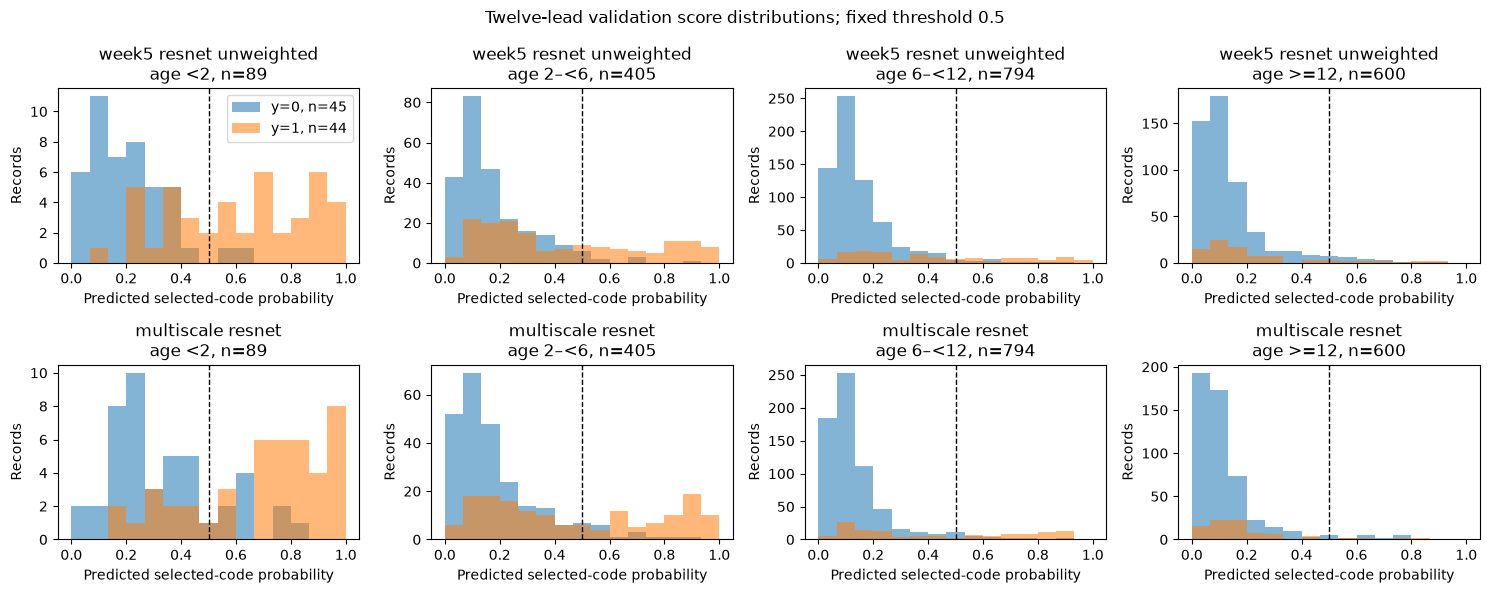

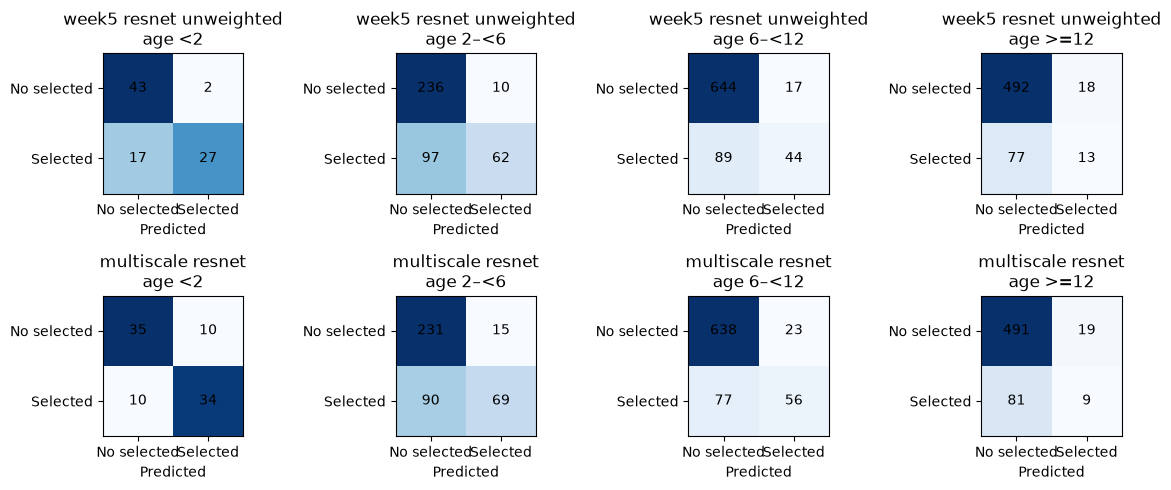

In [6]:
fig,axes=plt.subplots(2,4,figsize=(15,6),sharex=False)
for row,name in enumerate(models):
    for col,age in enumerate(labels):
        ax=axes[row,col];g=val12[val12.age_group==age]
        for target,color in [(0,'tab:blue'),(1,'tab:orange')]:
            v=g.loc[g.target==target,name+'_probability']
            ax.hist(v,bins=np.linspace(0,1,16),alpha=.55,color=color,label=f'y={target}, n={len(v)}')
        ax.axvline(.5,color='black',linestyle='--',linewidth=1)
        ax.set(title=f'{name.replace("_"," ")}\nage {age}, n={len(g)}',xlabel='Predicted selected-code probability',ylabel='Records')
        if row==0 and col==0:ax.legend()
fig.suptitle('Twelve-lead validation score distributions; fixed threshold 0.5')
fig.tight_layout();fig.savefig(OUT/'age_score_distributions_12lead.png',dpi=150)
plt.show()
fig,axes=plt.subplots(2,4,figsize=(12,5))
for row,name in enumerate(models):
    for col,age in enumerate(labels):
        m=metrics[(metrics.model==name)&(metrics.age_group==age)].iloc[0]
        ax=axes[row,col];cm=np.array([[m.tn,m.fp],[m.fn,m.tp]],dtype=int)
        ax.imshow(cm,cmap='Blues')
        for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center')
        ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['No selected','Selected'],
               yticklabels=['No selected','Selected'],title=f'{name.replace("_"," ")}\nage {age}',xlabel='Predicted')
fig.tight_layout();fig.savefig(OUT/'age_confusion_matrices_12lead.png',dpi=150)
plt.show()

In [7]:
# Recording duration is context for a model that sees only the first 10 seconds.
duration=val12.assign(duration_seconds=val12.sampling_point/FS)
duration_context=(duration.groupby('age_group',observed=True)
    .agg(records=('target','size'),patients=('patient_id','nunique'),
         median_duration_seconds=('duration_seconds','median'),
         q25_duration_seconds=('duration_seconds',lambda s:s.quantile(.25)),
         q75_duration_seconds=('duration_seconds',lambda s:s.quantile(.75)),
         records_longer_than_10s=('duration_seconds',lambda s:int((s>10).sum())))
    .reset_index())
duration_context.to_csv(OUT/'recording_duration_context_12lead.csv',index=False)
display(duration_context)
print('Patients appearing in more than one twelve-lead age bin:',
      int((val12.groupby('patient_id').age_group.nunique()>1).sum()))

,age_group,records,patients,median_duration_seconds,q25_duration_seconds,q75_duration_seconds,records_longer_than_10s
0,<2,89,85,30.0,30.0,30.0,89
1,2–<6,405,338,30.0,23.0,30.0,403
2,6–<12,794,655,30.0,21.0,30.0,791
3,>=12,600,477,30.0,20.0,30.0,599


Patients appearing in more than one twelve-lead age bin: 0


## Interpretation and limitations

**Measured twelve-lead validation results.** The primary cohort has 1,888 records from 1,555 patients (426 selected-code positives). Counts by age are <2 years: 89 records/85 patients/44 positives (49.4%); 2–<6: 405/338/159 (39.3%); 6–<12: 794/655/133 (16.8%); ≥12: 600/477/90 (15.0%). The corresponding nine-lead counts are 183, 90, 8, and 0 records, so nine-lead age-by-lead performance comparisons are not made. All metrics below use the fixed 0.5 threshold except AUROC/AP.

| Model | Age | Sensitivity | Specificity | AUROC | AP | TN / FP / FN / TP |
|---|---|---:|---:|---:|---:|---:|
| Week 5 ResNet | <2 | 0.614 | 0.956 | 0.912 | 0.922 | 43 / 2 / 17 / 27 |
| Week 5 ResNet | 2–<6 | 0.390 | 0.959 | 0.786 | 0.743 | 236 / 10 / 97 / 62 |
| Week 5 ResNet | 6–<12 | 0.331 | 0.974 | 0.817 | 0.571 | 644 / 17 / 89 / 44 |
| Week 5 ResNet | ≥12 | 0.144 | 0.965 | 0.635 | 0.273 | 492 / 18 / 77 / 13 |
| Multi-scale ResNet | <2 | 0.773 | 0.778 | 0.853 | 0.873 | 35 / 10 / 10 / 34 |
| Multi-scale ResNet | 2–<6 | 0.434 | 0.939 | 0.790 | 0.751 | 231 / 15 / 90 / 69 |
| Multi-scale ResNet | 6–<12 | 0.421 | 0.965 | 0.810 | 0.587 | 638 / 23 / 77 / 56 |
| Multi-scale ResNet | ≥12 | 0.100 | 0.963 | 0.672 | 0.271 | 491 / 19 / 81 / 9 |

**Observation:** both models miss most selected-code positive records at age ≥12 at the unchanged threshold, despite high specificity. The multi-scale model has higher sensitivity than the original in the first three age groups, with lower specificity; at ≥12 it has lower sensitivity. The patient-clustered descriptive 95% range for multi-scale sensitivity at ≥12 is roughly 0.024–0.188 and for the original ResNet 0.055–0.242. These are not independent test estimates. The paired model intervals for AP/AUROC span zero in every age group, so no stable subgroup superiority is established.

**Context, not explanation:** selected-code prevalence and the mixture of exact ICD strings vary with age; AP is prevalence-sensitive. The code-mix table counts records and may count one record under multiple selected codes. Twelve-lead restriction removes the strongest lead-count imbalance from the primary age comparison but does not control diagnosis mixture, recording context, signal quality, or other age-linked factors. The model sees only the first 10 seconds, although the median recording length is 30 seconds in every twelve-lead age group. Repeated records per patient make record-level estimates correlated; patient-clustered resampling partly reflects this. No causal reason for the age pattern or clinical disease-detection claim follows. This validation set was already used for model selection, and the frozen test set remains untouched.